# Лабораторная работа 2.2

In [2]:
import pandas as pd
from sklearn import linear_model as lm
from sklearn.preprocessing import PolynomialFeatures
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score, mean_absolute_percentage_error

In [28]:
FILEPATH = 'data/lab2_2_DS.csv'
df = pd.read_csv(FILEPATH)

X = df.iloc[:, 0] 
y = df.iloc[:, -1]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

poly2 = PolynomialFeatures(degree=2)
poly3 = PolynomialFeatures(degree=3)
poly8 = PolynomialFeatures(degree=8)

X_2_train = poly2.fit_transform(X_train.to_frame())
X_3_train = poly3.fit_transform(X_train.to_frame())
X_8_train = poly8.fit_transform(X_train.to_frame())

reg2 = lm.LinearRegression()
reg3 = lm.LinearRegression()
reg8 = lm.LinearRegression()

reg2.fit(X_2_train, y_train)
reg3.fit(X_3_train, y_train)
reg8.fit(X_8_train, y_train)

print(reg2.intercept_, reg2.coef_)
print(reg3.intercept_, reg3.coef_)
print(reg8.intercept_, reg8.coef_)


2.7683058295738583 [ 0.         -0.70641926  1.87145125]
2.8405309852828076 [ 0.         -1.39956426  1.87501919  0.05451597]
2.338791516219487 [ 0.00000000e+00 -3.36815619e+00  1.37516911e+00  5.40093880e-01
  1.34339148e-01 -3.38468041e-02 -7.23363003e-03  7.32208848e-04
  8.35712738e-05]


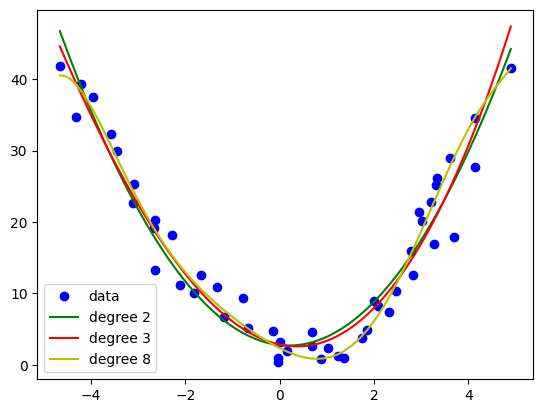

In [21]:
fig, ax = plt.subplots()

x = np.linspace(min(df['Temperature (°C)']), max(df['Temperature (°C)']), 100)

ax.plot(df['Temperature (°C)'], df['Ice Cream Sales (units)'], 'bo', label='data')

ax.plot(x, reg2.intercept_ + sum([x**i * reg2.coef_[i] for i in range(1,3)]), label='degree 2', color='g')
ax.plot(x, reg3.intercept_ + sum([x**i * reg3.coef_[i] for i in range(1,4)]), label='degree 3', color='r')
ax.plot(x, reg8.intercept_ + sum([x**i * reg8.coef_[i] for i in range(1,9)]), label='degree 8', color='y')

ax.legend()

In [26]:
models = {
    'Degree 2': reg2,
    'Degree 3': reg3,
    'Degree 8': reg8
}

poly = {
    'Degree 2': poly2,
    'Degree 3': poly3,
    'Degree 8': poly8
}

results = {}
for name, model in models.items():
    X_poly_test = poly[name].fit_transform(X_test.to_frame())

    y_pred = model.predict(X_poly_test)
    results[name] = {
        'MAE': mean_absolute_error(y_test, y_pred),
        'MAPE': mean_absolute_percentage_error(y_test, y_pred),
        'R2': r2_score(y_test, y_pred),
    }

table = pd.DataFrame(results).T
print(table)

               MAE      MAPE        R2
Degree 2  3.229982  0.687247  0.843055
Degree 3  3.228121  0.595957  0.840511
Degree 8  3.160702  0.333981  0.775960


Вывод: полином второй степени наиболее точно описывает зависимость среди представленных. Также можно заметить, что с увеличением степени результат ухудшается (как минимум при данном выборе степеней многочленов)